<a href="https://colab.research.google.com/github/NANCYSINGH6285/PMJDY-Financial-Inclusion/blob/main/PMJDY_Financial_Inclusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Project: Financial Inclusion under PMJDY
# Student: Nancy Singh

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step 1: Load the saved PMJDY state-wise dataset

# Load the cleaned dataset committed in this GitHub repository.
# This avoids depending on the PMJDY website's SSL certificate during every run.
DATA_URL = "https://raw.githubusercontent.com/NANCYSINGH6285/PMJDY-Financial-Inclusion/main/PMJDY_Statewise_Cleaned.csv"

try:
    df = pd.read_csv(DATA_URL)
    print("Dataset loaded from the project GitHub repository.")
except Exception as e:
    print("Could not download the project CSV:", e)
    print("Upload PMJDY_Statewise_Cleaned.csv in the Colab Files panel, then run this cell again.")
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv("PMJDY_Statewise_Cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded from the project GitHub repository.
Dataset shape: (36, 6)


,State Name,Beneficiaries at rural/semi-urban centre bank branches,Beneficiaries at urban/metro centre bank branches,Total Beneficiaries,Balance in beneficiary accounts (in crore),No. of RuPay cards issued to beneficiaries
0,Andaman And Nicobar Islands,47979,18558,66537,58.86,40304
1,Andhra Pradesh,12703904,4752477,17456381,6847.98,11468206
2,Arunachal Pradesh,460336,11769,472105,272.86,318996
3,Assam,23396349,2729942,26126291,7775.76,16745532
4,Bihar,61576091,9182084,70758175,32643.22,50997960


In [3]:
# Step 2: Validate and clean the state-wise dataset

df.columns = df.columns.str.strip()
df["State Name"] = df["State Name"].astype(str).str.strip()

numeric_columns = [
    "Beneficiaries at rural/semi-urban centre bank branches",
    "Beneficiaries at urban/metro centre bank branches",
    "Total Beneficiaries",
    "Balance in beneficiary accounts (in crore)",
    "No. of RuPay cards issued to beneficiaries"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["State Name"] + numeric_columns)
df = df[~df["State Name"].str.lower().isin(["total", "grand total", "all india"])]
df = df.drop_duplicates(subset=["State Name"]).reset_index(drop=True)

calculated_total = (
    df["Beneficiaries at rural/semi-urban centre bank branches"]
    + df["Beneficiaries at urban/metro centre bank branches"]
)
mismatch_count = int((calculated_total != df["Total Beneficiaries"]).sum())

print("Rows after cleaning:", len(df))
print("Unique states/UTs:", df["State Name"].nunique())
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate state/UT names:", int(df["State Name"].duplicated().sum()))
print("Rural + urban total mismatches:", mismatch_count)

if mismatch_count:
    print("Warning: Some rural + urban totals do not match the reported total. Review source data.")

df.to_csv("PMJDY_Statewise_Cleaned.csv", index=False)
display(df.head())

Rows after cleaning: 36
Unique states/UTs: 36
Missing values: 0
Duplicate state/UT names: 0
Rural + urban total mismatches: 0


,State Name,Beneficiaries at rural/semi-urban centre bank branches,Beneficiaries at urban/metro centre bank branches,Total Beneficiaries,Balance in beneficiary accounts (in crore),No. of RuPay cards issued to beneficiaries
0,Andaman And Nicobar Islands,47979,18558,66537,58.86,40304
1,Andhra Pradesh,12703904,4752477,17456381,6847.98,11468206
2,Arunachal Pradesh,460336,11769,472105,272.86,318996
3,Assam,23396349,2729942,26126291,7775.76,16745532
4,Bihar,61576091,9182084,70758175,32643.22,50997960


In [4]:

# Step 3: Create meaningful features for clustering

# Share of beneficiaries in rural/semi-urban centres
df["Rural Beneficiary Share (%)"] = (
    df["Beneficiaries at rural/semi-urban centre bank branches"]
    / df["Total Beneficiaries"] * 100
)

# Share of beneficiaries in urban/metro centres
df["Urban Beneficiary Share (%)"] = (
    df["Beneficiaries at urban/metro centre bank branches"]
    / df["Total Beneficiaries"] * 100
)

# Average account balance per beneficiary, in rupees
df["Average Balance per Beneficiary (Rs)"] = (
    df["Balance in beneficiary accounts (in crore)"]
    * 10_000_000
    / df["Total Beneficiaries"]
)

# RuPay cards issued per 100 beneficiaries
df["RuPay Cards per 100 Beneficiaries"] = (
    df["No. of RuPay cards issued to beneficiaries"]
    / df["Total Beneficiaries"] * 100
)

print("New features created successfully!")

display(df[[
    "State Name",
    "Total Beneficiaries",
    "Rural Beneficiary Share (%)",
    "Average Balance per Beneficiary (Rs)",
    "RuPay Cards per 100 Beneficiaries"
]].head(10))

print("\nFeature summary:")
display(df[[
    "Rural Beneficiary Share (%)",
    "Average Balance per Beneficiary (Rs)",
    "RuPay Cards per 100 Beneficiaries"
]].describe().round(2))

New features created successfully!


,State Name,Total Beneficiaries,Rural Beneficiary Share (%),Average Balance per Beneficiary (Rs),RuPay Cards per 100 Beneficiaries
0,Andaman And Nicobar Islands,66537,72.108752,8846.205870,60.573816
1,Andhra Pradesh,17456381,72.775130,3922.909336,65.696355
2,Arunachal Pradesh,472105,97.507122,5779.646477,67.568867
3,Assam,26126291,89.550978,2976.220390,64.094563
4,Bihar,70758175,87.023289,4613.349624,72.073594
5,Chandigarh,346746,14.763544,6441.602787,67.056001
6,Chhattisgarh,18938442,82.387696,4704.410215,61.762478
7,Delhi,7196111,9.198218,5699.231154,78.877174
8,Goa,242150,84.979971,10594.672724,71.968202
9,Gujarat,20233346,67.911061,6391.735702,76.708059



Feature summary:


,Rural Beneficiary Share (%),Average Balance per Beneficiary (Rs),RuPay Cards per 100 Beneficiaries
count,36.00,36.00,36.00
mean,74.09,6397.71,67.95
std,18.72,2768.88,6.17
min,9.20,2818.25,50.82
25%,69.06,4939.20,65.49
50%,76.42,5679.11,68.12
75%,85.49,6803.30,72.27
max,97.51,18048.52,78.88


In [5]:
# Step 4: Select features and scale the data

# Log transformation reduces the effect of very large beneficiary counts
df["Log Total Beneficiaries"] = np.log1p(df["Total Beneficiaries"])

# Features used for clustering
features = [
    "Log Total Beneficiaries",
    "Rural Beneficiary Share (%)",
    "Average Balance per Beneficiary (Rs)",
    "RuPay Cards per 100 Beneficiaries"
]

X = df[features].copy()

# Standardize all features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features selected:", features)
print("Original data shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)
print("\nScaled data preview:")

display(pd.DataFrame(X_scaled, columns=features).head(10).round(2))

Features selected: ['Log Total Beneficiaries', 'Rural Beneficiary Share (%)', 'Average Balance per Beneficiary (Rs)', 'RuPay Cards per 100 Beneficiaries']
Original data shape: (36, 4)
Scaled data shape: (36, 4)

Scaled data preview:


,Log Total Beneficiaries,Rural Beneficiary Share (%),Average Balance per Beneficiary (Rs),RuPay Cards per 100 Beneficiaries
0,-1.62,-0.11,0.90,-1.21
1,0.70,-0.07,-0.91,-0.37
2,-0.81,1.27,-0.23,-0.06
3,0.87,0.84,-1.25,-0.63
4,1.28,0.70,-0.65,0.68
5,-0.93,-3.21,0.02,-0.15
6,0.73,0.45,-0.62,-1.02
7,0.33,-3.52,-0.26,1.79
8,-1.08,0.59,1.54,0.66
9,0.76,-0.33,-0.00,1.44


,Number of Clusters (K),Inertia,Silhouette Score
0,2,103.010,0.278
1,3,79.081,0.315
2,4,57.125,0.283
3,5,46.647,0.297
4,6,39.086,0.240


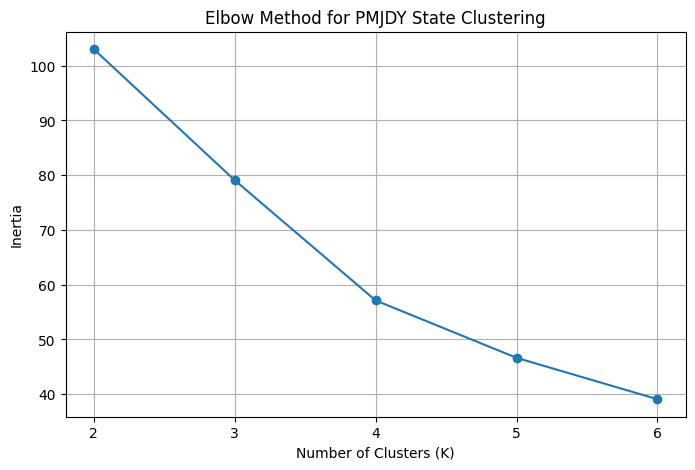

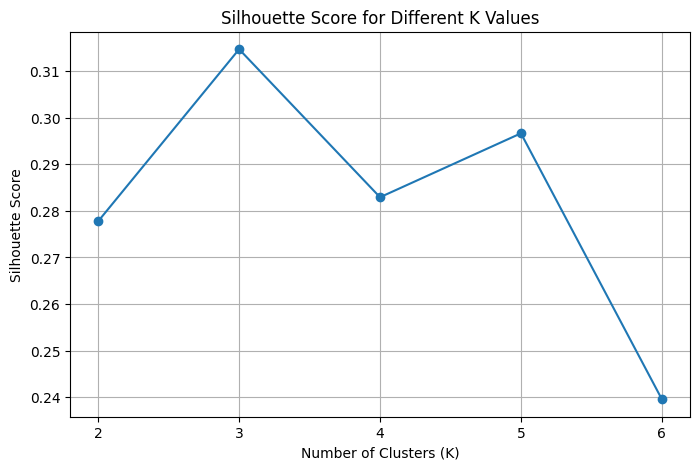

In [6]:
# Step 5: Compare different numbers of clusters

inertia_values = []
silhouette_values = []
k_values = range(2, 7)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )

results = pd.DataFrame({
    "Number of Clusters (K)": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(results.round(3))

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for PMJDY State Clustering")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Plot Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [7]:
# Step 6: Perform K-Means clustering with K = 4

kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

df["KMeans_Cluster"] = kmeans_final.fit_predict(X_scaled)

print("K-Means clustering completed!")
print("\nNumber of states/UTs in each cluster:")

display(
    df["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .to_frame("Number of States/UTs")
)

print("\nState-wise cluster assignments:")

display(
    df[[
        "State Name",
        "Total Beneficiaries",
        "Rural Beneficiary Share (%)",
        "Average Balance per Beneficiary (Rs)",
        "RuPay Cards per 100 Beneficiaries",
        "KMeans_Cluster"
    ]].sort_values("KMeans_Cluster")
)

K-Means clustering completed!

Number of states/UTs in each cluster:


,Number of States/UTs
Cluster,
0,15
1,5
2,14
3,2



State-wise cluster assignments:


,State Name,Total Beneficiaries,Rural Beneficiary Share (%),Average Balance per Beneficiary (Rs),RuPay Cards per 100 Beneficiaries,KMeans_Cluster
4,Bihar,70758175,87.023289,4613.349624,72.073594,0
13,Jharkhand,20842819,90.015012,6164.645963,68.423216,0
10,Haryana,11372462,57.528229,7438.767437,69.794887,0
9,Gujarat,20233346,67.911061,6391.735702,76.708059,0
30,Telangana,13568681,72.160964,4463.926892,69.429261,0
23,Nagaland,410693,75.850575,3756.333807,75.774118,0
18,Madhya Pradesh,47954470,77.875764,4253.555508,74.748706,0
19,Maharashtra,38907301,69.694991,5615.066951,71.947687,0
24,Odisha,24403551,88.153089,5654.127959,74.202332,0
26,Punjab,10188919,62.611451,5560.854886,73.698711,0


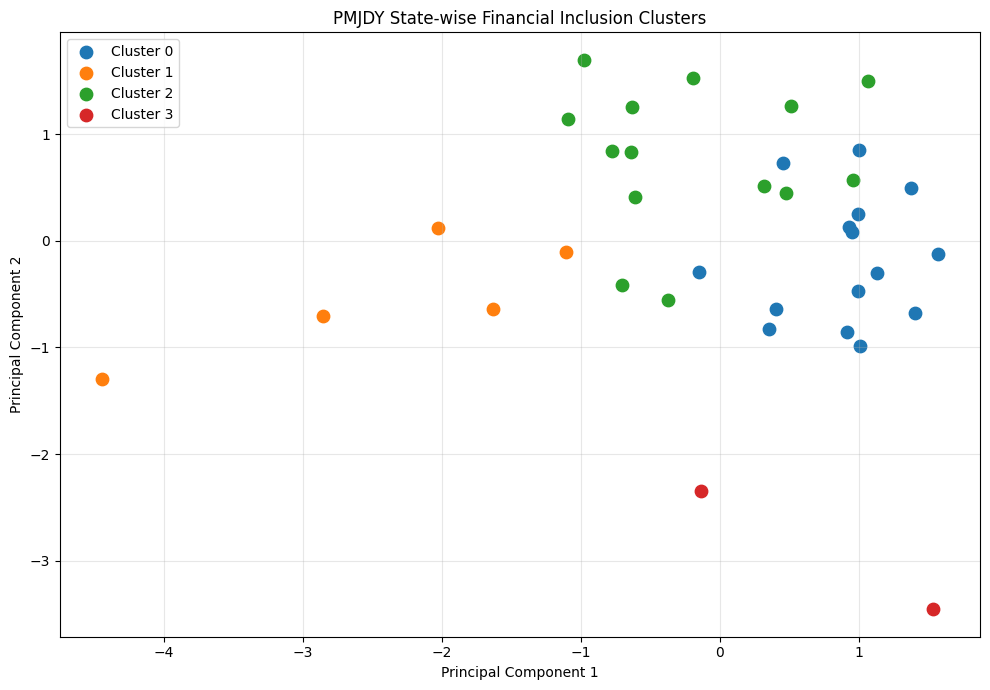

Variance explained by two PCA components: 69.75 %


In [8]:
# Step 7: Visualize K-Means clusters using PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df["PCA1"] = X_pca[:, 0]
df["PCA2"] = X_pca[:, 1]

plt.figure(figsize=(10, 7))

for cluster in sorted(df["KMeans_Cluster"].unique()):
    cluster_data = df[df["KMeans_Cluster"] == cluster]

    plt.scatter(
        cluster_data["PCA1"],
        cluster_data["PCA2"],
        label=f"Cluster {cluster}",
        s=80
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PMJDY State-wise Financial Inclusion Clusters")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("PMJDY_KMeans_Clusters.png", dpi=300)
plt.show()

print(
    "Variance explained by two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [9]:
# Step 8: Analyse the characteristics of each cluster

# Note: cluster IDs are arbitrary labels, not rankings.

cluster_profile = df.groupby("KMeans_Cluster").agg(
    Number_of_States=("State Name", "count"),
    Average_Beneficiaries=("Total Beneficiaries", "mean"),
    Average_Rural_Share=("Rural Beneficiary Share (%)", "mean"),
    Average_Balance_Rs=("Average Balance per Beneficiary (Rs)", "mean"),
    Average_RuPay_Indicator=("RuPay Cards per 100 Beneficiaries", "mean")
).round(2)

print("Cluster Profiles:")
display(cluster_profile)

# Save cluster assignments and profiles
df.to_csv("PMJDY_Clustered_States.csv", index=False)
cluster_profile.to_csv("PMJDY_Cluster_Profiles.csv")

print("Files saved successfully!")

Cluster Profiles:


,Number_of_States,Average_Beneficiaries,Average_Rural_Share,Average_Balance_Rs,Average_RuPay_Indicator
KMeans_Cluster,,,,,
0,15,32427551.20,74.76,5599.43,72.07
1,5,118436.60,83.46,11588.25,68.30
2,14,7268687.93,78.89,5446.00,62.70
3,2,3771428.50,11.98,6070.42,72.97


Files saved successfully!


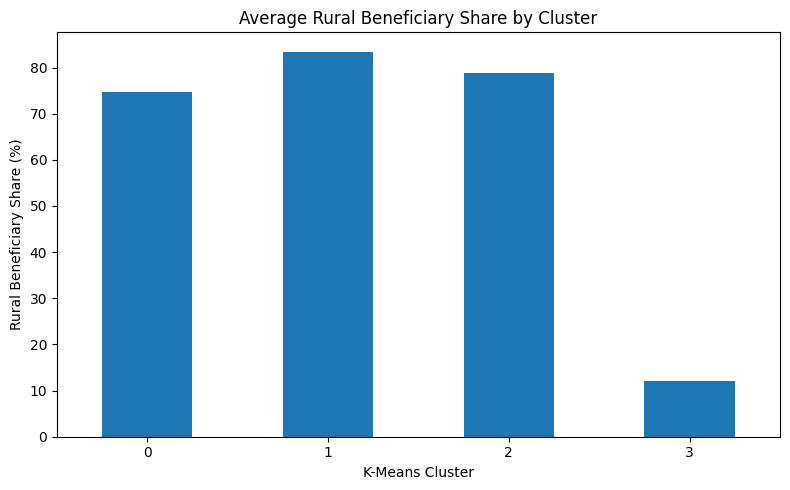

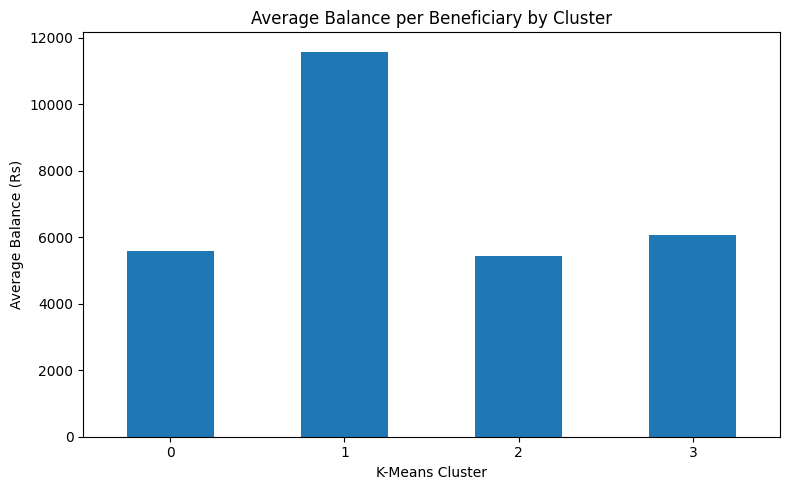

Final charts and CSV files saved successfully!

Saved files:
1. PMJDY_Clustered_States.csv
2. PMJDY_Cluster_Profiles.csv
3. PMJDY_KMeans_Clusters.png
4. PMJDY_Rural_Share_by_Cluster.png
5. PMJDY_Balance_by_Cluster.png


In [10]:
# Step 9: Final charts and project outputs

# Chart 1: Average rural beneficiary share by cluster
plt.figure(figsize=(8, 5))

cluster_profile["Average_Rural_Share"].plot(
    kind="bar",
    rot=0
)

plt.title("Average Rural Beneficiary Share by Cluster")
plt.xlabel("K-Means Cluster")
plt.ylabel("Rural Beneficiary Share (%)")
plt.tight_layout()
plt.savefig("PMJDY_Rural_Share_by_Cluster.png", dpi=300)
plt.show()


# Chart 2: Average balance per beneficiary by cluster
plt.figure(figsize=(8, 5))

cluster_profile["Average_Balance_Rs"].plot(
    kind="bar",
    rot=0
)

plt.title("Average Balance per Beneficiary by Cluster")
plt.xlabel("K-Means Cluster")
plt.ylabel("Average Balance (Rs)")
plt.tight_layout()
plt.savefig("PMJDY_Balance_by_Cluster.png", dpi=300)
plt.show()


# Save final dataset and cluster profile
df.to_csv("PMJDY_Clustered_States.csv", index=False)
cluster_profile.to_csv("PMJDY_Cluster_Profiles.csv")

print("Final charts and CSV files saved successfully!")
print("\nSaved files:")
print("1. PMJDY_Clustered_States.csv")
print("2. PMJDY_Cluster_Profiles.csv")
print("3. PMJDY_KMeans_Clusters.png")
print("4. PMJDY_Rural_Share_by_Cluster.png")
print("5. PMJDY_Balance_by_Cluster.png")

In [11]:
# Step 10: Download the final project outputs (optional)

# Run this cell in Google Colab if you want to download the generated CSV files and charts.
from google.colab import files

for filename in [
    "PMJDY_Statewise_Cleaned.csv",
    "PMJDY_Clustered_States.csv",
    "PMJDY_Cluster_Profiles.csv",
    "PMJDY_KMeans_Clusters.png",
    "PMJDY_Rural_Share_by_Cluster.png",
    "PMJDY_Balance_by_Cluster.png"
]:
    files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>